In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [2]:
from ucimlrepo import fetch_ucirepo

In [6]:
wine = fetch_ucirepo(id=109)
type(wine)

ucimlrepo.dotdict.dotdict

In [7]:
wine.keys()

dict_keys(['data', 'metadata', 'variables'])

In [8]:
wine.data.keys()

dict_keys(['ids', 'features', 'targets', 'original', 'headers'])

In [14]:
X = wine.data.features
print(X.shape)
X.head()


(178, 13)


,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [28]:
y = wine.data.targets
y.tail()

,class
173,3
174,3
175,3
176,3
177,3


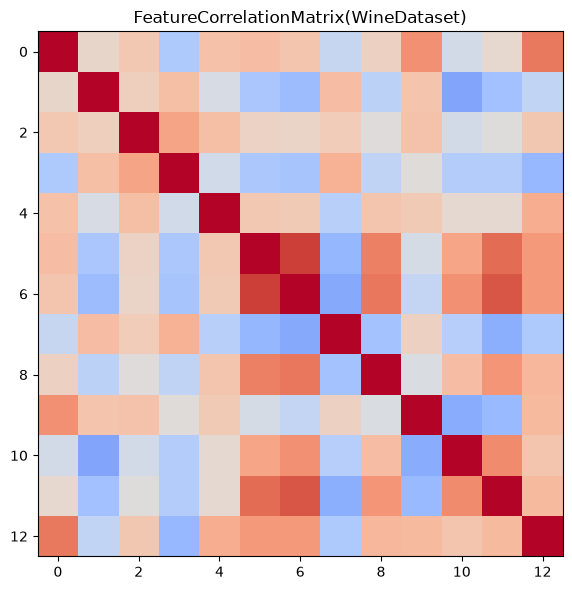

In [17]:
plt.figure(figsize=(8,6))
corr = X.corr()
plt.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1)
plt.title("FeatureCorrelationMatrix(WineDataset)") 
plt.tight_layout()
plt.show()

In [18]:
scalar = StandardScaler()
X_scaled = scalar.fit_transform(X)

In [29]:
pca = PCA()
pca.fit_transform(X_scaled)

array([[ 3.31675081e+00,  1.44346263e+00, -1.65739045e-01, ...,
        -4.51563395e-01,  5.40810414e-01, -6.62386309e-02],
       [ 2.20946492e+00, -3.33392887e-01, -2.02645737e+00, ...,
        -1.42657306e-01,  3.88237741e-01,  3.63650247e-03],
       [ 2.51674015e+00,  1.03115130e+00,  9.82818670e-01, ...,
        -2.86672847e-01,  5.83573183e-04,  2.17165104e-02],
       ...,
       [-2.67783946e+00,  2.76089913e+00, -9.40941877e-01, ...,
         5.12492025e-01,  6.98766451e-01,  7.20776948e-02],
       [-2.38701709e+00,  2.29734668e+00, -5.50696197e-01, ...,
         2.99821968e-01,  3.39820654e-01, -2.18657605e-02],
       [-3.20875816e+00,  2.76891957e+00,  1.01391366e+00, ...,
        -2.29964331e-01, -1.88787963e-01, -3.23964720e-01]],
      shape=(178, 13))

In [31]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
Data = load_wine()
Data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

In [35]:
X = Data.data
X.shape

(178, 13)

In [39]:
type(X)

numpy.ndarray

In [42]:
df = pd.DataFrame(data=X,columns=Data.feature_names)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [45]:
y = Data.target
y.shape

(178,)

In [54]:
X_train,X_test,y_train,y_test = train_test_split(df,y,train_size=0.8,random_state=20)

In [55]:
type(X_train)

pandas.DataFrame

In [56]:
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.fit_transform(X_test)

In [57]:
type(X_train_scaled)

numpy.ndarray

In [65]:
knn_unscaled = KNeighborsClassifier(n_neighbors=5,weights="distance",metric="minkowski")
knn_unscaled.fit(X_train,y_train)
y_pred=knn_unscaled.predict(X_test)
y_pred

array([1, 1, 0, 2, 1, 1, 2, 1, 1, 2, 0, 2, 2, 2, 0, 1, 1, 0, 0, 2, 2, 1,
       1, 0, 1, 2, 0, 1, 1, 1, 2, 1, 1, 2, 0, 0])

In [ ]:
y_test

array([1, 2, 0, 1, 1, 1, 2, 1, 1, 2, 0, 2, 1, 1, 0, 1, 1, 0, 0, 2, 2, 0,
       1, 0, 2, 1, 0, 2, 1, 1, 1, 1, 2, 1, 0, 0])

In [71]:
n = len(y_test)

In [74]:
count = 0
for i in range(n):
    if y_pred[i] != y_test[i]:
        count+=1
count 

11

In [77]:
accuracy = ((n-count)/n) * 100
accuracy

69.44444444444444

In [78]:
accuracy_score(y_pred=y_pred,y_true=y_test)

0.6944444444444444

In [79]:
knn_unscaled = KNeighborsClassifier(n_neighbors=5,weights="distance",metric="minkowski")
knn_unscaled.fit(X_train_scaled,y_train)
y_pred=knn_unscaled.predict(X_test_scaled)
y_pred

array([1, 2, 0, 1, 1, 1, 2, 1, 1, 2, 0, 2, 1, 1, 0, 1, 1, 0, 0, 2, 2, 0,
       1, 0, 2, 1, 0, 2, 1, 1, 1, 1, 2, 1, 0, 0])

In [81]:
y_test

array([1, 2, 0, 1, 1, 1, 2, 1, 1, 2, 0, 2, 1, 1, 0, 1, 1, 0, 0, 2, 2, 0,
       1, 0, 2, 1, 0, 2, 1, 1, 1, 1, 2, 1, 0, 0])

In [80]:
accuracy_score(y_pred=y_pred,y_true=y_test)

1.0

In [82]:
knn_unscaled = KNeighborsClassifier(n_neighbors=5,weights="uniform",metric="minkowski")
knn_unscaled.fit(X_train_scaled,y_train)
y_pred=knn_unscaled.predict(X_test_scaled)
y_pred

array([1, 2, 0, 1, 1, 1, 2, 1, 1, 2, 0, 2, 1, 1, 0, 1, 1, 0, 0, 2, 2, 0,
       1, 0, 2, 1, 0, 2, 1, 1, 0, 1, 2, 1, 0, 0])

In [83]:
accuracy_score(y_pred=y_pred,y_true=y_test)

0.9722222222222222